# Pretrain model yolo26n-seg

## SetUp

### Import Library

In [2]:
from glob import glob
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt 
from ultralytics import YOLO
from roboflow import Roboflow
from dotenv import load_dotenv

In [3]:
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["PYTORCH_MPS_HIGH_WATERMARK_RATIO"] = "0.0"
os.environ["PYTORCH_ENABLE_MPS_FALLBACK"] = "1"

### Set SEED

In [4]:
SEED = 2345

os.environ['PYTHONHASHSEED'] = str(SEED)

### Load .env

In [5]:
load_dotenv()

robowflow_api_key = os.getenv("ROBOWFLOW_API_KEY")

## Crop Image for labels Datasets 

In [191]:
def load_fish_image(filepath="../data/test_fish/*.jpg"):
  files = sorted(glob(filepath), key=lambda x: int(x.split("-")[-1].split(".")[0]))
  images = []

  for file in files:
    fish_img = cv2.imread(file)
    if fish_img is not None:
      fish_rgb = cv2.cvtColor(fish_img, cv2.COLOR_BGR2RGB)
      # print(f"Loaded: {file} | Shape: {fish_rgb.shape}")
      file_name = file.split("/")[-1].split(".")[0]
      h, w, _ = fish_rgb.shape
      images.append({"name": file_name, 
                     "height": h,
                     "width": w,
                     "pixel_array": fish_rgb})
    else:
      print(f"Warning: Dowload {file} fail!!!")

  return images  

In [ ]:
def crops_fish_image(crop_size=640, crops_per_img=2):
  images = load_fish_image()

  cropped_images = []

  rng = np.random.default_rng(seed=SEED)

  output_dir = "../data/fish_cropped_images"
  os.makedirs(output_dir, exist_ok=True)

  for image in images:
    if image["height"] < crop_size or image["width"] < crop_size:
      continue

    for crop_idx in range(1, crops_per_img + 1):
      max_y = image["height"] - crop_size
      max_x = image["width"] - crop_size

      start_y = rng.integers(0, max_y)
      start_x = rng.integers(0, max_x)

      cropped_img = image["pixel_array"][start_y:start_y + crop_size, start_x:start_x + crop_size]
      name = f"{image["name"]}_{crop_idx}"

      cropped_images.append({"name": name, "pixel_array": cropped_img})

  total_crops = len(cropped_images)

  if total_crops == 0:
    return

  ncols = 4
  nrows = (np.ceil(total_crops / ncols)).astype(int)

  fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, nrows * 3.5))
  axes = axes.flatten()

  for i in range(total_crops):
    crop = cropped_images[i]["pixel_array"]
    name = cropped_images[i]["name"]
    
    axes[i].imshow(crop)
    axes[i].set_title(name, fontsize=10)
    axes[i].axis('off')

    save_img = cv2.cvtColor(crop, cv2.COLOR_RGB2BGR)

    output_path = os.path.join(output_dir, f"{name}.jpg")
    success = cv2.imwrite(output_path, save_img)

    if not success:
      print(f"[Warning] can't save this file: {output_path}")
      print(f"  Shape: {save_img.shape}, Dtype: {save_img.dtype}")

  for j in range(total_crops, len(axes)):
    axes[j].axis('off')

  plt.tight_layout()
  plt.show()

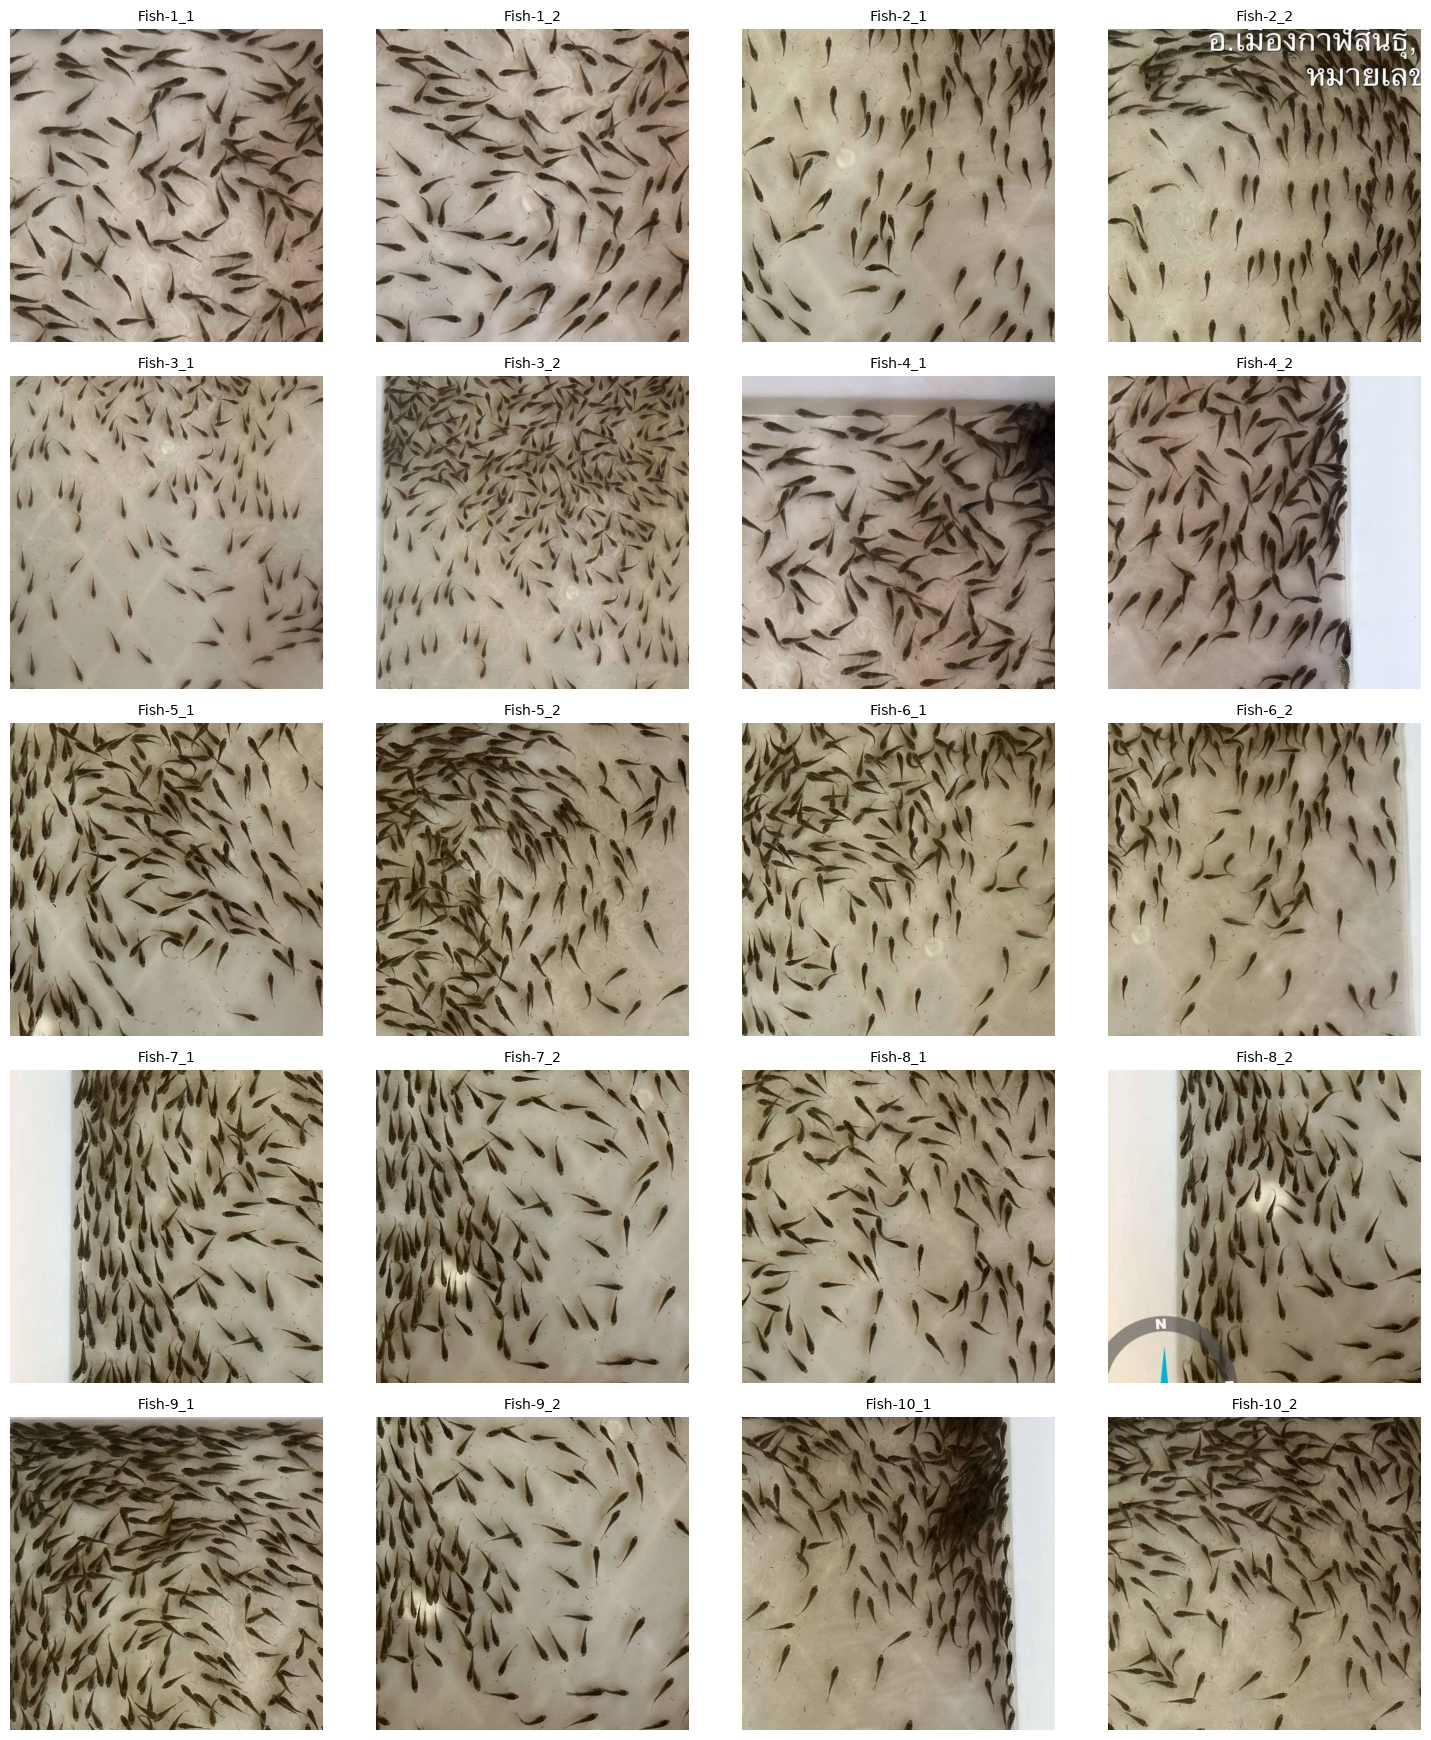

In [194]:
crops_fish_image()

## Train with 5 images

### Dowload dataset from roblowflow


Dataset: ../data/fish_dataset_5_images <br>
Train: 13 images | Val: 1 image <br>
Data Augmentation:
- Outputs per training example: 3
- Flip: Horizontal, Vertical
- Rotation: Between -15° and +15°
- Grayscale: Apply to 15% of images
- Brightness: Between -25% and +25%
- Blur: Up to 4px
- Noise: Up to 1.96% of pixels

In [208]:
rf = Roboflow(api_key=robowflow_api_key)
project = rf.workspace("phitchakorns-workspace").project("fish_count-ekvlc")
version = project.version(3)
dataset = version.download(
  model_format="yolov8",
  location="../data/fish_dataset_5_images"
  )

loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to ../data/fish_dataset_5_images in yolov8:: 100%|██████████| 29/29 [00:00<00:00, 1315.91it/s]


#### Show train sample images

In [217]:
def show_train_samples_yolo(data_dir="../data/fish_dataset_5_images/train", num_samples=3):
    img_files = sorted(glob(f"{data_dir}/images/*.jpg"))
    
    if not img_files:
        print("not found images")
        return

    selected_files = img_files[:num_samples]
    
    fig, axes = plt.subplots(nrows=len(selected_files), ncols=3, figsize=(15, 5 * len(selected_files)))
    if len(selected_files) == 1:
        axes = np.expand_dims(axes, axis=0)

    for idx, img_path in enumerate(selected_files):
        img_bgr = cv2.imread(img_path)
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        h, w, _ = img_rgb.shape

        label_path = img_path.replace("/images/", "/labels/").rsplit(".", 1)[0] + ".txt"
        
        mask = np.zeros((h, w), dtype=np.uint8)

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                lines = f.readlines()
                for line in lines:
                    parts = list(map(float, line.strip().split()))
                    
                    if len(parts) > 5:
                        coords = np.array(parts[1:], dtype=np.float32).reshape(-1, 2)
                        coords[:, 0] *= w 
                        coords[:, 1] *= h 
                        pts = coords.astype(np.int32)
                        cv2.fillPoly(mask, [pts], color=255)

        overlay = img_rgb.copy()
        color_mask = np.zeros_like(img_rgb)
        color_mask[mask > 0] = [0, 255, 0]
        overlay = cv2.addWeighted(overlay, 1.0, color_mask, 0.5, 0)

        axes[idx, 0].imshow(img_rgb)
        axes[idx, 0].set_title(f"Image", fontsize=10)
        axes[idx, 0].axis("off")

        axes[idx, 1].imshow(mask, cmap="gray")
        axes[idx, 1].set_title("Mask", fontsize=10)
        axes[idx, 1].axis("off")

        axes[idx, 2].imshow(overlay)
        axes[idx, 2].set_title("Image + Mask Overlay", fontsize=10)
        axes[idx, 2].axis("off")

    plt.tight_layout()
    plt.show()

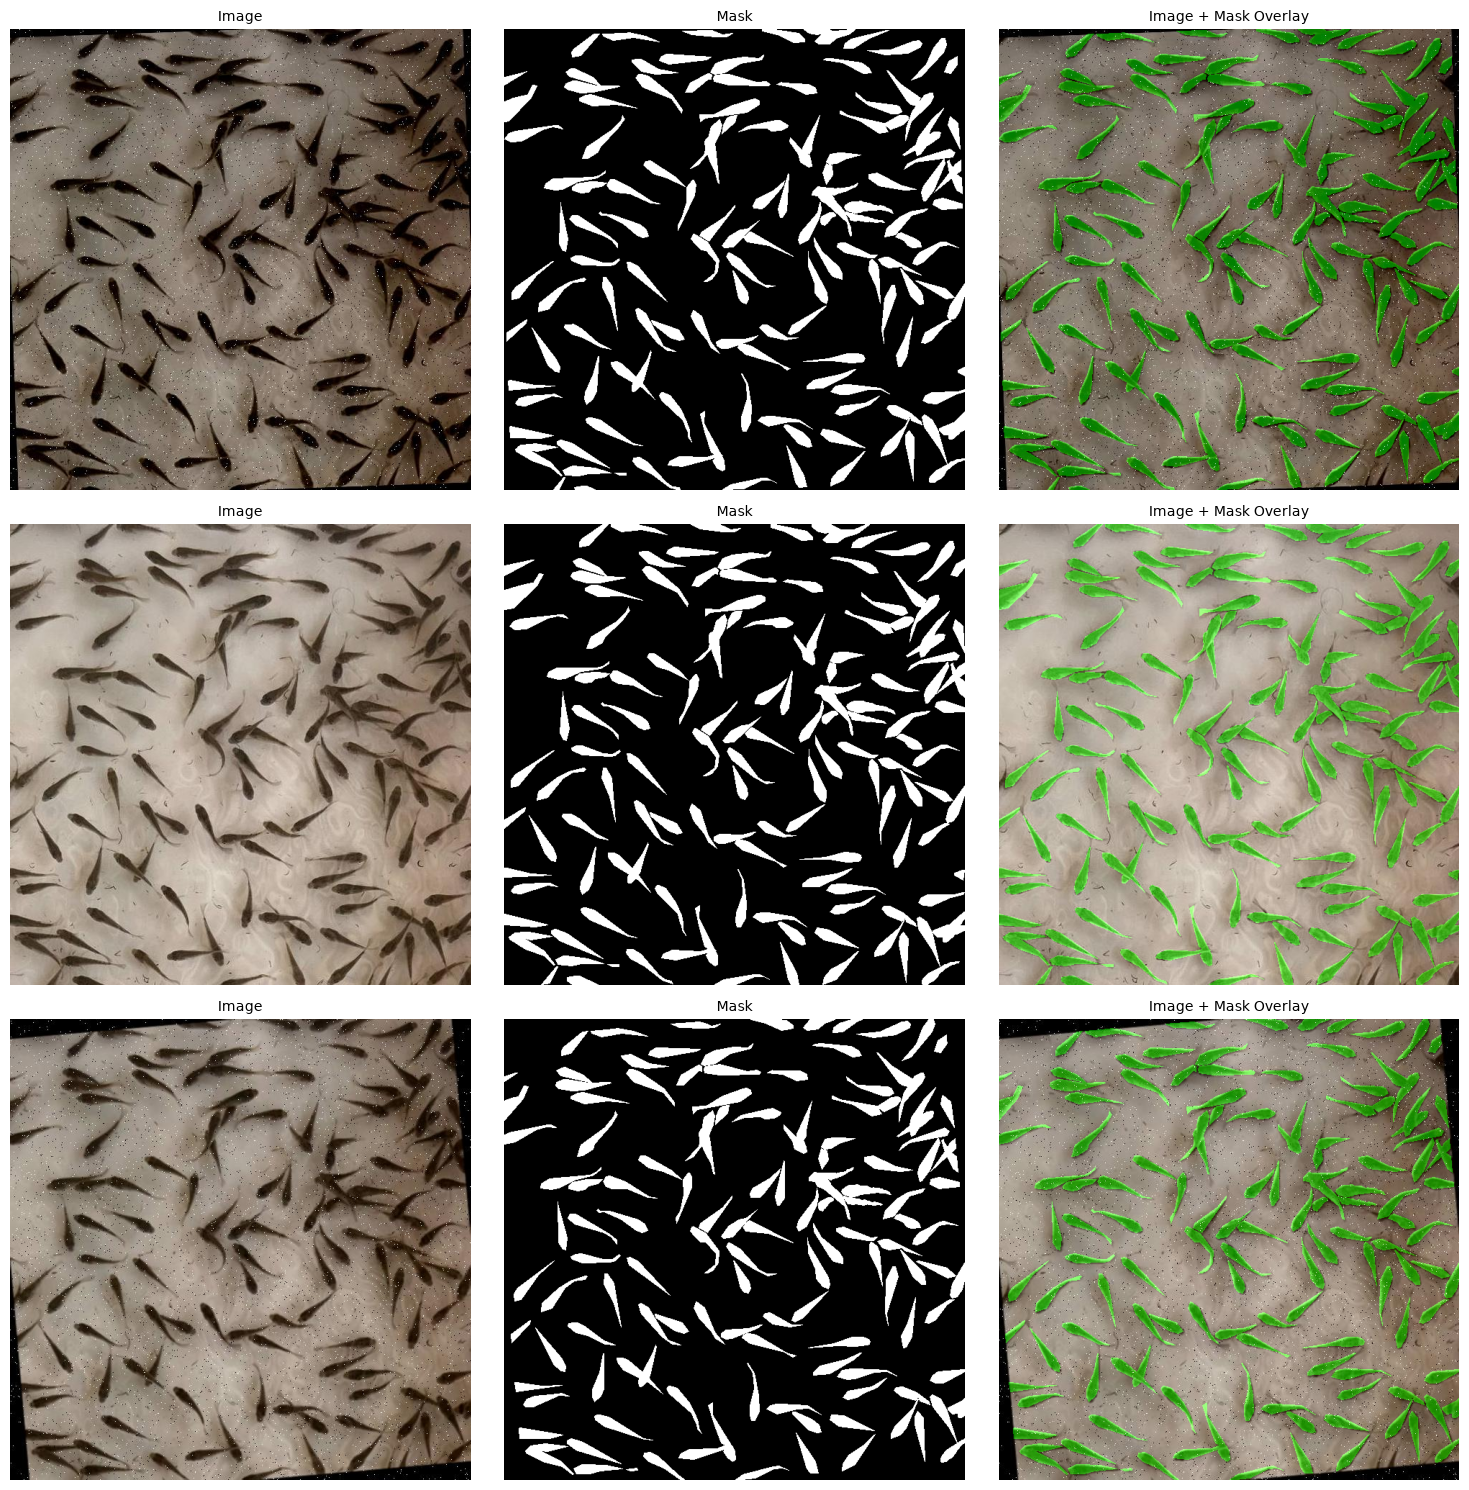

In [218]:
show_train_samples_yolo()

### Train Model

In [5]:
model = YOLO("../models/yolo26n-seg.pt")

In [6]:
results = model.train(
    data="../data/fish_dataset_5_images/data.yaml",   
    epochs=100,             
    imgsz=640,              
    batch=4,                
    device="cpu",          
    workers=0,            
    patience=8,             
    save=True,    
    cache=False,           
    project="../models/fish_counting_seg_v1",
    name="train_5_images_ep1",      
    exist_ok=True,
    seed=SEED
)

New https://pypi.org/project/ultralytics/8.4.202 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.194 🚀 Python-3.12.4 torch-2.15.0 CPU (Apple M3)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=4, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=../data/fish_dataset_5_images/data.yaml, degrees=0.0, deterministic=True, device=cpu, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=../models/yolo26n-seg.pt, mo

### Evaluation

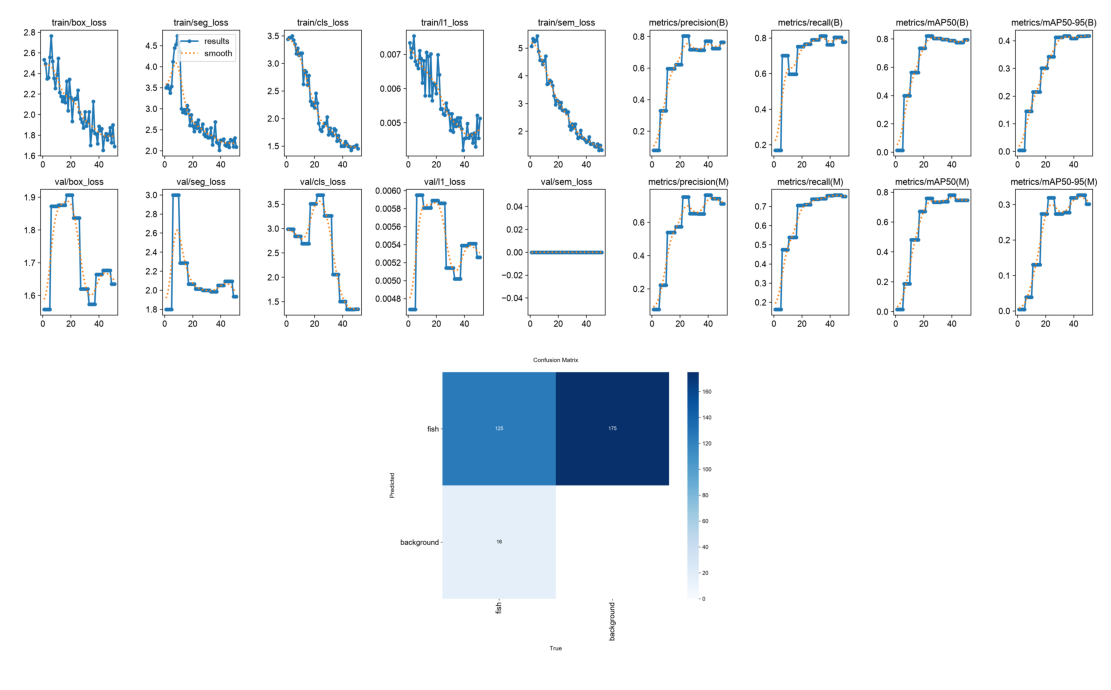

In [15]:
fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(15, 2 * 3.5))
  
axes[0].imshow(cv2.imread('../runs/models/fish_counting_seg_v1/train_5_images_ep1/results.png')[:, :, ::-1])
axes[0].axis('off')

axes[1].imshow(cv2.imread('../runs/models/fish_counting_seg_v1/train_5_images_ep1/confusion_matrix.png')[:, :, ::-1])
axes[1].axis('off')

plt.tight_layout()
plt.show()

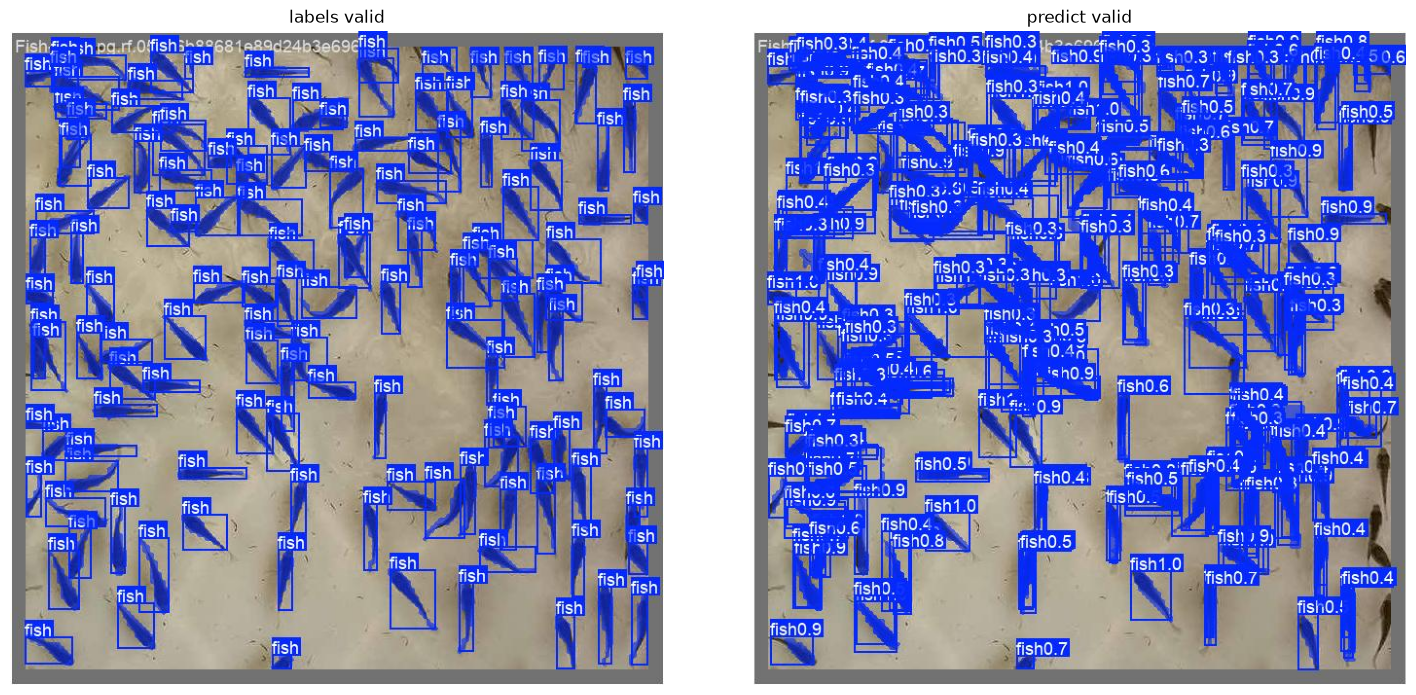

In [19]:
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 2 * 3.5))
axes.flatten()
  
axes[0].imshow(cv2.imread('../runs/models/fish_counting_seg_v1/train_5_images_ep1/val_batch0_labels.jpg')[:, :, ::-1])
axes[0].set_title('labels valid')
axes[0].axis('off')

axes[1].imshow(cv2.imread('../runs/models/fish_counting_seg_v1/train_5_images_ep1/val_batch0_pred.jpg')[:, :, ::-1])
axes[1].set_title('predict valid')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### Summary

จากผลที่ได้มา ทำให้ทราบว่าเกิดจากปัญาที่พยายาม label ปลาที่ซ้อนกันให้แยกจากกันเพื่อให้นับปลาได้ละเอียดครบทุกตัวที่สุด ทำให้โมเดลเรียนรู้ผิดโดยกาเข้าใจว่าปลาหนึ่งตัวซ้อนกันหลายตัวทั้งหมด ทำให้ปลาหนึ่งตัวก็ถูกนับว่าซ้อนกันหมด <br><br>
จึงจะแก้ไขด้วยการ label ปลาแค่ตัวที่เห็นชัดเจนเต็มตัวและเอาแค่ปลาตัวที่อยู่บนสุดเท่านั้น